# Potential outcomes, by hand: drug or surgery?

**Question:** a hospital treats patients with a drug or with surgery. Surgery patients do *worse* on average. Should
the hospital stop operating?

This notebook is the first three weeks of the course (potential outcomes, identifiability, conditioning) run on a
simulator where, unlike in real life, **both** potential outcomes of every patient are known. So every quantity the
lectures define (the ATE, the biases, what randomization buys) can be computed exactly and compared with what an
analyst would estimate.

| § | Idea | Lecture |
|---|---|---|
| 1 | Simpson's paradox: the pooled comparison and the per-severity comparison disagree | Introduction |
| 2 | Potential outcomes $Y_i(0), Y_i(1)$, and the table we want vs the table we have | PO: definitions |
| 3 | Naive difference = ATE + baseline bias + differential-effect bias, checked numerically | PO: identifiability |
| 4 | Randomization makes the naive difference unbiased | PO: identifiability |
| 5 | Conditional randomization and conditional ignorability | PO: identifiability |
| 6 | Matching: which population is the estimate about? | PO: estimation |
| 7 | Conditioning (stratification): residual confounding and positivity | PO: estimation |
| 8 | Confidence intervals: CLT vs Hoeffding | PO: estimation |
| 9 | **slider:** confounding strength vs naive bias | |

The simulator is [`src/hospital.py`](../src/hospital.py): severity $S \sim U(0, 2)$, surgery with probability
$\sigma(3(S-1))$, baseline remission $0.9 - 0.35 S$, and a surgery effect $\tau(S) = -0.15 + 0.25 S$ that is
negative for mild patients and positive for severe ones. The true ATE is $0.10$.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w

from src.hospital import make_hospital, severity_bucket
from src import estimators as E

plt.rcParams["figure.dpi"] = 100
DRUG, SURG = "tab:blue", "tab:orange"
BUCKETS = ["low", "medium", "high"]

d = make_hospital(n=2000, seed=0)
print(f"{len(d.Y)} patients, {int(d.T.sum())} operated on")
print(f"true ATE = {d.ate:+.3f}   ATT = {d.att:+.3f}   ATC = {d.atc:+.3f}")

2000 patients, 1005 operated on
true ATE = +0.099   ATT = +0.192   ATC = +0.006


## 1. Simpson's paradox

First, what the hospital's database shows: mean remission score by treatment, pooled over everybody, and then
within each severity bucket the physician assigns (low / medium / high).

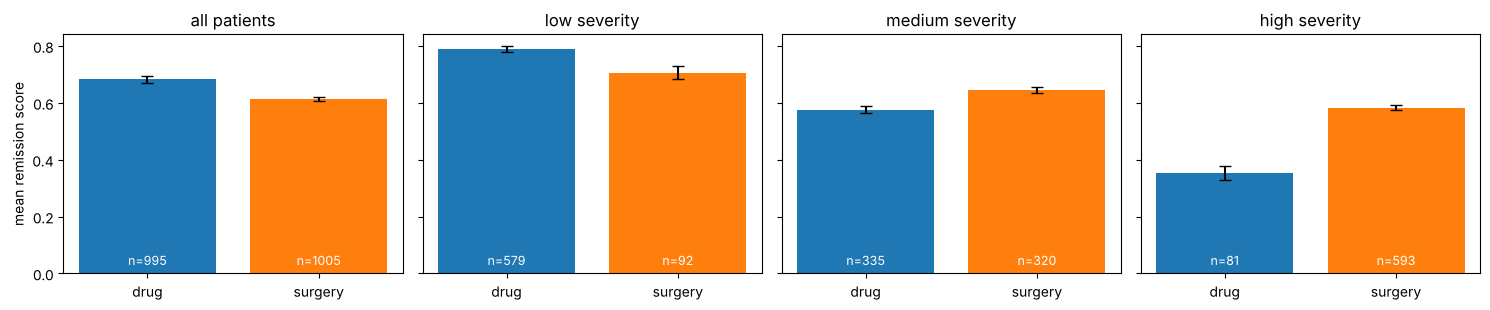

pooled difference (surgery - drug): -0.068


In [2]:
b = severity_bucket(d.S)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
def bars(ax, m, title):
    for t, col, lab in [(0, DRUG, "drug"), (1, SURG, "surgery")]:
        y = d.Y[m & (d.T == t)]
        ax.bar(t, y.mean(), color=col, yerr=1.96 * y.std() / np.sqrt(len(y)), capsize=4)
        ax.text(t, 0.03, f"n={len(y)}", ha="center", color="white", fontsize=9)
    ax.set_xticks([0, 1], ["drug", "surgery"]); ax.set_title(title)
bars(axes[0], np.ones_like(d.T, bool), "all patients")
for k in range(3):
    bars(axes[k + 1], b == k, f"{BUCKETS[k]} severity")
axes[0].set_ylabel("mean remission score")
plt.tight_layout(); plt.show()
print(f"pooled difference (surgery - drug): {E.naive_difference(d.X, d.T, d.Y).ate:+.3f}")

Pooled, surgery looks worse. Within the medium and high buckets surgery is clearly better (and slightly worse for low
severity, which is true: $\tau(S) < 0$ for $S < 0.6$). The pooled comparison is dominated by **who** gets surgery:
mostly severe patients, who do worse whatever they receive. Comparing non-comparable groups gives an arbitrarily bad
prediction of what a decision would do.

## 2. The table we want and the table we have

For each patient $i$ there are two **potential outcomes**: $Y_i(0)$ under the drug and $Y_i(1)$ under surgery. The
individual effect is $Y_i(1) - Y_i(0)$. We only ever see the one that matches the treatment received,
$Y_i = T_i Y_i(1) + (1 - T_i) Y_i(0)$ (consistency, part of SUTVA).

In [3]:
idx = np.argsort(d.S[:20])
print(f"{'patient':>8} {'severity':>8} | {'Y(0)':>6} {'Y(1)':>6} {'effect':>7} || {'T':>2} {'Y(0)':>6} {'Y(1)':>6} {'effect':>7}")
print("-" * 8 + "-" * 10 + "+" + "-" * 22 + "++" + "-" * 25)
for i in idx:
    obs0 = f"{d.Y0[i]:.2f}" if d.T[i] == 0 else "?"
    obs1 = f"{d.Y1[i]:.2f}" if d.T[i] == 1 else "?"
    print(f"{i:>8} {d.S[i]:>8.2f} | {d.Y0[i]:>6.2f} {d.Y1[i]:>6.2f} {d.Y1[i]-d.Y0[i]:>+7.2f} || "
          f"{int(d.T[i]):>2} {obs0:>6} {obs1:>6} {'?':>7}")
print("\nleft: what we want (simulator only)        right: what we have (any real dataset)")

 patient severity |   Y(0)   Y(1)  effect ||  T   Y(0)   Y(1)  effect
------------------+----------------------++-------------------------
      11     0.01 |   0.82   0.67   -0.15 ||  0   0.82      ?       ?
       3     0.03 |   0.77   0.63   -0.14 ||  0   0.77      ?       ?
      13     0.07 |   0.90   0.77   -0.13 ||  0   0.90      ?       ?
       2     0.08 |   0.80   0.67   -0.13 ||  0   0.80      ?       ?
      15     0.35 |   0.86   0.79   -0.06 ||  0   0.86      ?       ?
       1     0.54 |   0.72   0.70   -0.02 ||  1      ?   0.70       ?
      18     0.60 |   0.81   0.81   -0.00 ||  1      ?   0.81       ?
      19     0.85 |   0.44   0.50   +0.06 ||  0   0.44      ?       ?
      17     1.08 |   0.65   0.77   +0.12 ||  0   0.65      ?       ?
       8     1.09 |   0.39   0.52   +0.12 ||  1      ?   0.52       ?
       6     1.21 |   0.43   0.58   +0.15 ||  0   0.43      ?       ?
       0     1.27 |   0.31   0.48   +0.17 ||  0   0.31      ?       ?
       7     1.46 |  

Causal inference is a missing-data problem: half of the left table is missing, and *which* half is missing depends on
severity. Individual effects are never observed, so we target population averages:

$$\text{ATE} = E[Y(1) - Y(0)], \qquad \text{ATT} = E[Y(1) - Y(0) \mid T = 1], \qquad \text{ATC} = E[Y(1) - Y(0) \mid T = 0].$$

Here ATT > ATE > ATC, because the treated are the severe patients for whom surgery helps most.

## 3. Why the naive difference is wrong, term by term

The lecture's "expectation kung-fu" shows that

$$
E[Y|T=1] - E[Y|T=0] = \underbrace{E[Y(1) - Y(0)]}_{\text{ATE}}
+ \underbrace{E[Y(0)|T=1] - E[Y(0)|T=0]}_{\text{baseline bias}}
+ \underbrace{(1-\pi)\big(E[Y(1)-Y(0)|T=1] - E[Y(1)-Y(0)|T=0]\big)}_{\text{differential treatment effect bias}}
$$

with $\pi = P(T=1)$. In the simulator every term is computable, so we can check the identity exactly (on the sample).

naive difference          -0.0683
ATE                       +0.0995
baseline bias             -0.2601   (operated patients would do worse even on the drug)
differential effect bias  +0.0923   (and they benefit more from surgery)
sum of the three terms    -0.0683


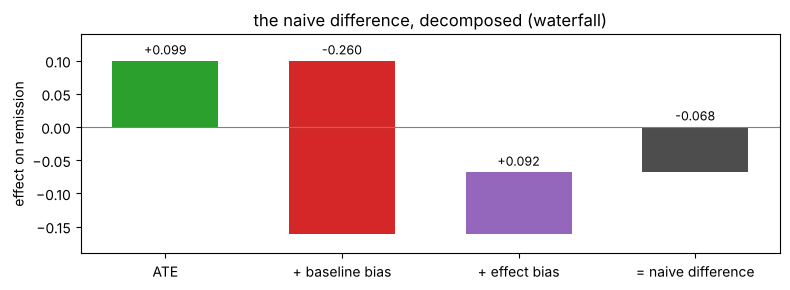

In [4]:
T, Y0, Y1 = d.T == 1, d.Y0, d.Y1
pi = T.mean()
naive = d.Y[T].mean() - d.Y[~T].mean()
ate = (Y1 - Y0).mean()
baseline_bias = Y0[T].mean() - Y0[~T].mean()
effect_bias = (1 - pi) * ((Y1 - Y0)[T].mean() - (Y1 - Y0)[~T].mean())
print(f"naive difference          {naive:+.4f}")
print(f"ATE                       {ate:+.4f}")
print(f"baseline bias             {baseline_bias:+.4f}   (operated patients would do worse even on the drug)")
print(f"differential effect bias  {effect_bias:+.4f}   (and they benefit more from surgery)")
print(f"sum of the three terms    {ate + baseline_bias + effect_bias:+.4f}")

fig, ax = plt.subplots(figsize=(8, 3))
steps = [("ATE", 0, ate, "tab:green"), ("+ baseline bias", ate, ate + baseline_bias, "tab:red"),
         ("+ effect bias", ate + baseline_bias, naive, "tab:purple"), ("= naive difference", 0, naive, "0.3")]
for k, (lab, a, b, c) in enumerate(steps):
    ax.bar(k, b - a, bottom=a, color=c, width=0.6)
    ax.text(k, max(a, b) + 0.01, f"{b - a:+.3f}", ha="center", fontsize=9)
ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(4), [s[0] for s in steps])
lo = min(0, ate + baseline_bias, naive) - 0.03; hi = max(0, ate) + 0.04
ax.set_ylim(lo, hi); ax.set_ylabel("effect on remission"); ax.set_title("the naive difference, decomposed (waterfall)")
plt.tight_layout(); plt.show()

The baseline bias is large and negative: it is the gap in *drug* outcomes between the two groups, i.e. pure
confounding by severity. The effect bias is positive but smaller. Their sum flips the sign of the ATE.

Both biases vanish under **(mean) ignorability**, $E[Y(t)|T=1] = E[Y(t)|T=0]$, or its full version
$\{Y(0), Y(1)\} \perp\!\!\!\perp T$. Then $\text{ATE} = E[Y|T=1] - E[Y|T=0]$: the ATE is **identified**, written in
terms of observable quantities only.

## 4. Randomization gives ignorability by design

Assign surgery with a fair coin. The same patients, the same potential outcomes; only the assignment changes. Repeat
the whole study 300 times to see the sampling distribution of the naive difference in each world.

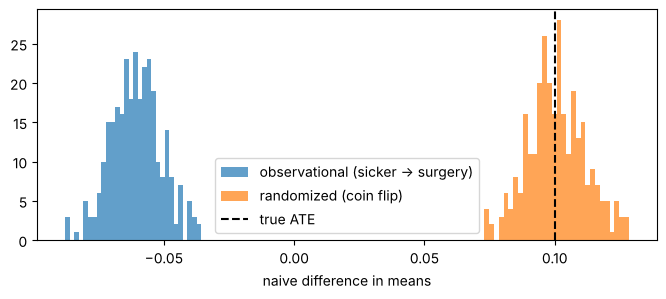

observational: mean -0.061 (bias -0.161)
randomized   : mean +0.101 (bias +0.001), sd 0.011


In [5]:
obs, rct = [], []
for s in range(300):
    obs.append(E.naive_difference(*make_hospital(1000, seed=s)[:3]).ate)
    rct.append(E.naive_difference(*make_hospital(1000, seed=s, randomized=True)[:3]).ate)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(obs, 30, alpha=0.7, label="observational (sicker -> surgery)")
ax.hist(rct, 30, alpha=0.7, label="randomized (coin flip)")
ax.axvline(0.10, color="k", ls="--", label="true ATE")
ax.set_xlabel("naive difference in means"); ax.legend(); plt.show()
print(f"observational: mean {np.mean(obs):+.3f} (bias {np.mean(obs) - 0.10:+.3f})")
print(f"randomized   : mean {np.mean(rct):+.3f} (bias {np.mean(rct) - 0.10:+.3f}), sd {np.std(rct):.3f}")

Randomizing does not change anyone's potential outcomes; it changes who is compared with whom. Treatment status is
now independent of $(Y(0), Y(1))$, so the two arms are exchangeable and the difference in means is unbiased. (The
probability does not have to be $1/2$; any constant works.)

## 5. Conditional randomization

The doctors suspect surgery helps severe patients, so they randomize with $P(T=1) = 0.8$ if $S \ge 1$ and $0.2$
otherwise. Ignorability fails again (assignment depends on severity, which drives outcomes), but **conditional
ignorability** $\{Y(0), Y(1)\} \perp\!\!\!\perp T \mid \mathbb{1}[S \ge 1]$ holds, so the ATE is identified by
conditioning:

$$\text{ATE} = \sum_{s \in \{0,1\}} P(S_{\ge 1} = s)\,\big(E[Y|T=1, S_{\ge 1}=s] - E[Y|T=0, S_{\ge 1}=s]\big).$$

In [6]:
dc = make_hospital(4000, seed=1, randomized=True)
rng = np.random.default_rng(12345)   # a separate stream for the doctors' coin
high = (dc.S >= 1).astype(int)
Tc = (rng.uniform(size=len(high)) < np.where(high, 0.8, 0.2)).astype(float)
Yc = Tc * dc.Y1 + (1 - Tc) * dc.Y0
print(f"true ATE                           {dc.ate:+.3f}")
print(f"naive difference                   {E.naive_difference(dc.X, Tc, Yc).ate:+.3f}")
s = E.stratified(high, Tc, Yc)
print(f"conditioning on 1[S >= 1]          {s.ate:+.3f}  (95% CI {s.ci()[0]:+.3f} .. {s.ci()[1]:+.3f})")

true ATE                           +0.099
naive difference                   -0.040
conditioning on 1[S >= 1]          +0.094  (95% CI +0.085 .. +0.104)


## 6. Matching

Without any randomization, matching tries to *build* exchangeable groups: for each patient, find the most similar
patient (here: closest severity) in the other arm and use their outcome as the missing potential outcome.

Two things the lecture asks you to notice:

* **No comparable pairs everywhere.** The mildest surgery patients and the most severe drug patients are rare, so
  their matches are far away.
* **Which population?** Matching each treated unit to a control estimates the ATT; matching each control to a treated
  unit estimates the ATC; doing both gives the ATE.

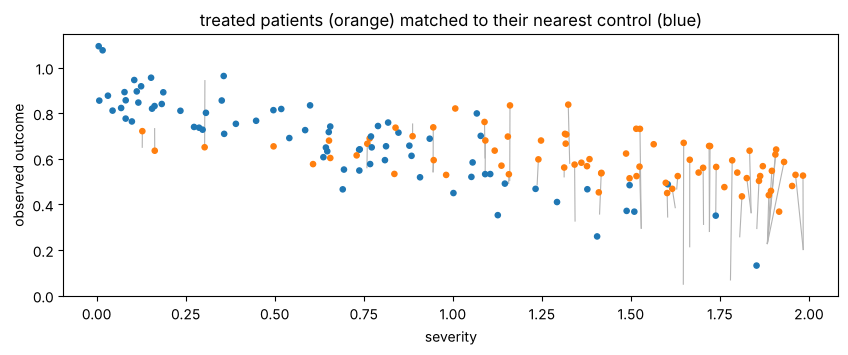

matching estimate of the ATT: +0.192   (truth +0.192)
matching estimate of the ATC: +0.009   (truth +0.006)
matching estimate of the ATE: +0.101   (truth +0.099)


In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
sub = np.random.default_rng(0).choice(len(d.Y), 150, replace=False)
ctrl = np.where(d.T == 0)[0]
for i in sub[d.T[sub] == 1][:40]:
    j = ctrl[np.argmin(np.abs(d.S[ctrl] - d.S[i]))]
    ax.plot([d.S[i], d.S[j]], [d.Y[i], d.Y[j]], color="0.7", lw=0.8, zorder=1)
ax.scatter(d.S[sub], d.Y[sub], c=np.where(d.T[sub] == 1, SURG, DRUG), s=14, zorder=2)
ax.set_xlabel("severity"); ax.set_ylabel("observed outcome"); ax.set_title("treated patients (orange) matched to their nearest control (blue)")
plt.show()
for target, truth in [("att", d.att), ("atc", d.atc), ("ate", d.ate)]:
    m = E.matching(d.X, d.T, d.Y, target=target)
    print(f"matching estimate of the {target.upper()}: {m.ate:+.3f}   (truth {truth:+.3f})")

Matching recovers each estimand because, *in this simulator*, severity is the only confounder. That is the "no free
lunch" of the lecture: ignorability links observed $(T, X)$ to unobservable $(Y(0), Y(1))$ and cannot be verified from
the data. If the doctors also used something we do not record, every estimator in this repository is biased, and only
the methods of [10](../../../10-instruments-and-discontinuities/) or a sensitivity analysis
([07](../../../07-causal-deep-learning/)) can help.

## 7. Conditioning: residual confounding and positivity

The stratified estimator is only as good as the strata. Three-bucket severity leaves confounding *within* each bucket
(sicker patients inside "high" still get more surgery). Finer strata remove it, until strata become so small that some
contain only one arm.

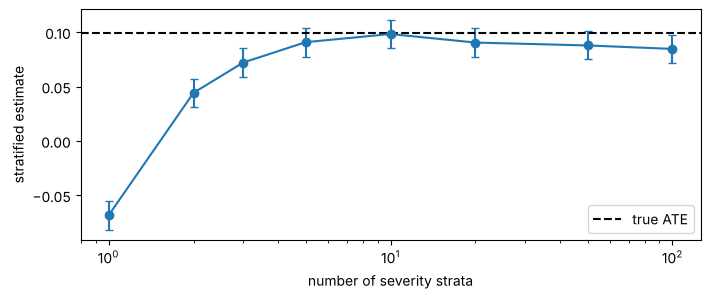

strata  estimate   strata without both arms  population kept
     1    -0.068                          0           100.0%
     2    +0.044                          0           100.0%
     3    +0.072                          0           100.0%
     5    +0.091                          0           100.0%
    10    +0.098                          0           100.0%
    20    +0.090                          1            95.0%
    50    +0.088                          5            90.1%
   100    +0.085                         27            74.5%


In [8]:
ks = [1, 2, 3, 5, 10, 20, 50, 100]
rows = []
for k in ks:
    strata = np.minimum((d.S / 2 * k).astype(int), k - 1)
    s = E.stratified(strata, d.T, d.Y)
    rows.append((k, s.ate, s.se, len(s.info["dropped"]), s.info["mass_kept"]))
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(ks, [r[1] for r in rows], yerr=[1.96 * r[2] for r in rows], fmt="o-", capsize=3)
ax.axhline(d.ate, color="k", ls="--", label="true ATE"); ax.set_xscale("log")
ax.set_xlabel("number of severity strata"); ax.set_ylabel("stratified estimate"); ax.legend(); plt.show()
print(f"{'strata':>6} {'estimate':>9} {'strata without both arms':>26} {'population kept':>16}")
for k, a, se, nd, mk in rows:
    print(f"{k:>6} {a:>+9.3f} {nd:>26} {mk:>16.1%}")

**Positivity** ($0 < P(T=1|X=x) < 1$ for every $x$) is the second assumption of identification. Make the doctors
nearly deterministic (propensity slope 30 instead of 3): almost every stratum then contains only one arm, and the
estimate is about a shrinking, unrepresentative sliver of patients.

In [9]:
dp = make_hospital(4000, seed=0, strength=30.0, clip=0.0)
for k in [3, 10, 30]:
    strata = np.minimum((dp.S / 2 * k).astype(int), k - 1)
    s = E.stratified(strata, dp.T, dp.Y)
    print(f"{k:>3} strata: estimate {s.ate:+.3f} on {s.info['mass_kept']:.0%} of patients (true ATE {dp.ate:+.3f})")

  3 strata: estimate +0.023 on 34% of patients (true ATE +0.098)
 10 strata: estimate +0.091 on 31% of patients (true ATE +0.098)
 30 strata: estimate +0.093 on 20% of patients (true ATE +0.098)


## 8. How confident are we? CLT vs Hoeffding

Identification says *what* to estimate; statistical inference says how far the estimate can be from it. For one
stratum mean $\bar Y_{t,x}$ (outcomes clipped to $[0, 1]$):

* **CLT**: $\bar Y \pm 1.96\, S / \sqrt{N}$, asymptotically valid;
* **Hoeffding**: $\bar Y \pm \sqrt{\ln(2/\delta) / (2N)}$, valid for every $N$ but loose, since it only uses the range.

Coverage over 2000 repetitions:

In [10]:
def coverage(N, reps=2000, delta=0.05):
    rng = np.random.default_rng(0)
    mu_true = None
    big = np.clip(make_hospital(200000, seed=99).Y0, 0, 1); mu_true = big.mean()
    hits_clt = hits_h = 0; w_clt = w_h = 0
    for r in range(reps):
        y = rng.choice(big, N)
        se = y.std(ddof=1) / np.sqrt(N); h = np.sqrt(np.log(2 / delta) / (2 * N))
        hits_clt += abs(y.mean() - mu_true) <= 1.96 * se; hits_h += abs(y.mean() - mu_true) <= h
        w_clt += 2 * 1.96 * se; w_h += 2 * h
    return hits_clt / reps, hits_h / reps, w_clt / reps, w_h / reps
print(f"{'N':>5} | {'CLT coverage':>12} {'width':>7} | {'Hoeffding cov.':>14} {'width':>7}")
for N in [5, 20, 100, 500]:
    c1, c2, wc, wh = coverage(N)
    print(f"{N:>5} | {c1:>12.1%} {wc:>7.3f} | {c2:>14.1%} {wh:>7.3f}")

    N | CLT coverage   width | Hoeffding cov.   width
    5 |        87.6%   0.378 |         100.0%   1.215
   20 |        93.7%   0.195 |         100.0%   0.607


  100 |        94.6%   0.088 |         100.0%   0.272


  500 |        94.8%   0.039 |         100.0%   0.121


Hoeffding always covers but is about 3-4x wider here, because the outcome's spread is much smaller than its range.
The CLT interval is tight and close to nominal once $N$ is moderate. Causal estimators add a twist: the variance
depends on the weights the estimator gives each stratum, which is why later estimators (IPW, AIPW, DML) come with their
own standard-error formulas.

## 9. Slider: how much confounding does it take?

Drag the slope of the propensity in severity. At 0 the study is randomized; as the doctors become more
severity-driven, the naive difference moves away from the ATE and the stratified estimate (10 strata) stays close
until positivity starts to fail.

In [11]:
def confounding(strength=3.0):
    ests = {"naive": [], "10 strata": []}
    for s in range(30):
        dd = make_hospital(1500, seed=s, strength=strength, clip=0.0)
        ests["naive"].append(E.naive_difference(dd.X, dd.T, dd.Y).ate)
        st = np.minimum((dd.S / 2 * 10).astype(int), 9)
        ests["10 strata"].append(E.stratified(st, dd.T, dd.Y).ate)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3), gridspec_kw=dict(width_ratios=[1, 1.4]))
    ss = np.linspace(0, 2, 200)
    ax.plot(ss, 1 / (1 + np.exp(-strength * (ss - 1))), color=SURG); ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("severity"); ax.set_ylabel("P(surgery | severity)"); ax.set_title(f"propensity, slope {strength:g}")
    ax2.boxplot(list(ests.values()), orientation="horizontal", tick_labels=list(ests.keys()))
    ax2.axvline(0.10, color="k", ls="--"); ax2.set_xlim(-0.35, 0.3); ax2.set_title("30 replications, dashed = true ATE")
    plt.tight_layout(); plt.show()

w.interact(confounding, strength=w.FloatSlider(value=3.0, min=0.0, max=20.0, step=0.5));

interactive(children=(FloatSlider(value=3.0, description='strength', max=20.0, step=0.5), Output()), _dom_clas…

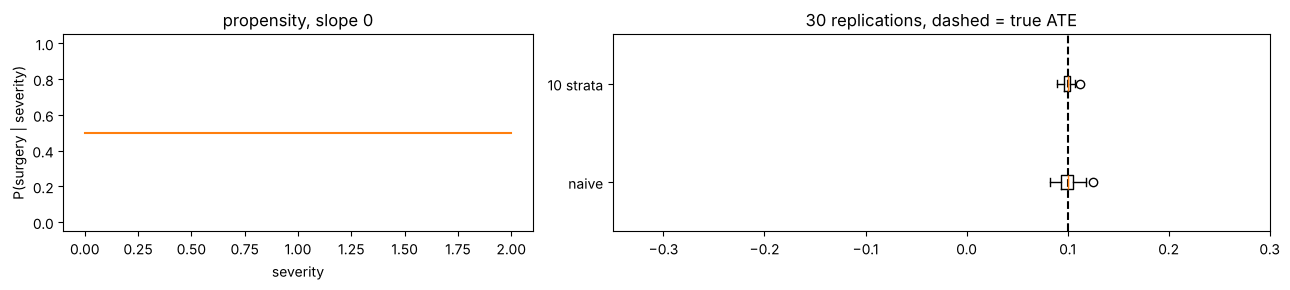

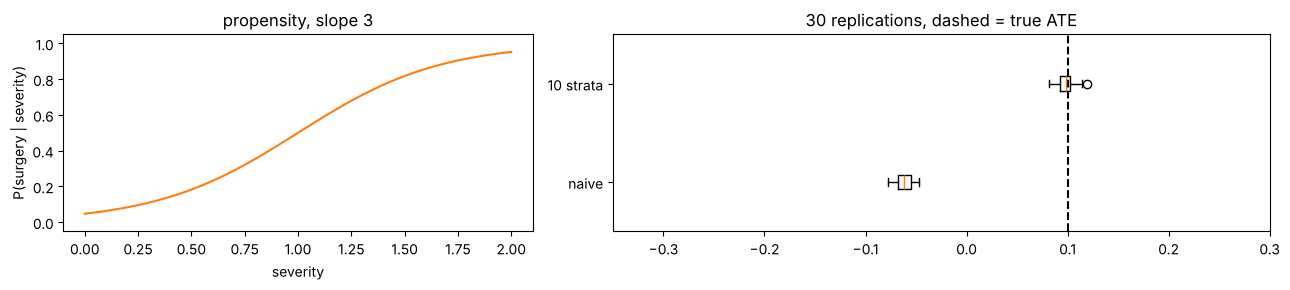

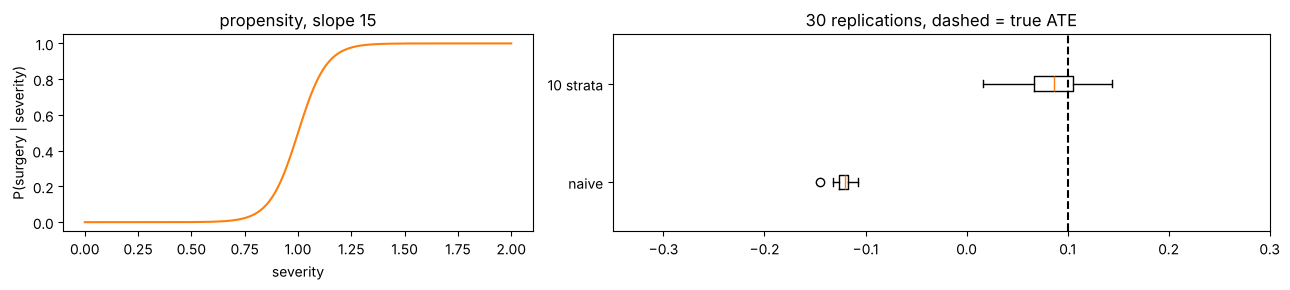

In [12]:
for s in [0.0, 3.0, 15.0]:
    confounding(s)

## What carries over

* Everything later in the course is a way to estimate $E\big[E[Y|T=1,X] - E[Y|T=0,X]\big]$ when stratifying by hand
  is impossible: [regression](../../../02-regression/) models $E[Y|T,X]$, [propensity
  scores](../../../03-propensity-scores/) condition on a one-dimensional summary of $X$, and
  [12](../../../12-one-dataset-many-estimators/) runs all of them on this same hospital with more covariates.
* The two assumptions never go away: **conditional ignorability** (untestable; [06](../../../06-structural-causal-models/)
  gives a language to argue for it) and **positivity** (testable, and the reason later estimators clip propensities).